In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
# Setting logging to print only error messages from sklearn
import logging
logging.basicConfig()
logging.getLogger("SKLEARNEX").setLevel(logging.ERROR)
# Data Preprocessing
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

# Machine Learning
import scipy.cluster.hierarchy as sch
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import calinski_harabasz_score




#Load Data

In [2]:
from sklearn.datasets import load_iris
# Load the dataset
iris = load_iris()
# Convert the the DataFrame
df = pd.DataFrame(data= iris.data, columns= iris.feature_names)
# Add the target columns
df['target']= iris.target
df['species']= pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   target             150 non-null    int64   
 5   species            150 non-null    category
dtypes: category(1), float64(4), int64(1)
memory usage: 6.3 KB


In [4]:
df.duplicated().sum()

np.int64(1)

In [5]:
duplicates = df[df.duplicated(keep=False)]
display(duplicates)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
101,5.8,2.7,5.1,1.9,2,virginica
142,5.8,2.7,5.1,1.9,2,virginica


In [6]:
df.drop_duplicates(inplace=True)

In [7]:
df.shape

(149, 6)

In [8]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,149.000000,149.000000,149.000000,149.000000,149.000000
mean,5.843624,3.059732,3.748993,1.194631,0.993289
std,0.830851,0.436342,1.767791,0.762622,0.817847
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.300000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [9]:
df['target'].value_counts()

,count
target,
0,50
1,50
2,49


In [10]:
df['species'].unique(), df['species'].value_counts()

(['setosa', 'versicolor', 'virginica']
 Categories (3, object): ['setosa', 'versicolor', 'virginica'],
 species
 setosa        50
 versicolor    50
 virginica     49
 Name: count, dtype: int64)

# Train-Test slipt data

In [11]:
from sklearn.model_selection import train_test_split
trainset, testset = train_test_split(df, test_size=0.2, random_state=42)

In [12]:
trainset.shape, testset.shape

((119, 6), (30, 6))

#EDA

##Univariate

In [13]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


<function matplotlib.pyplot.show(close=None, block=None)>

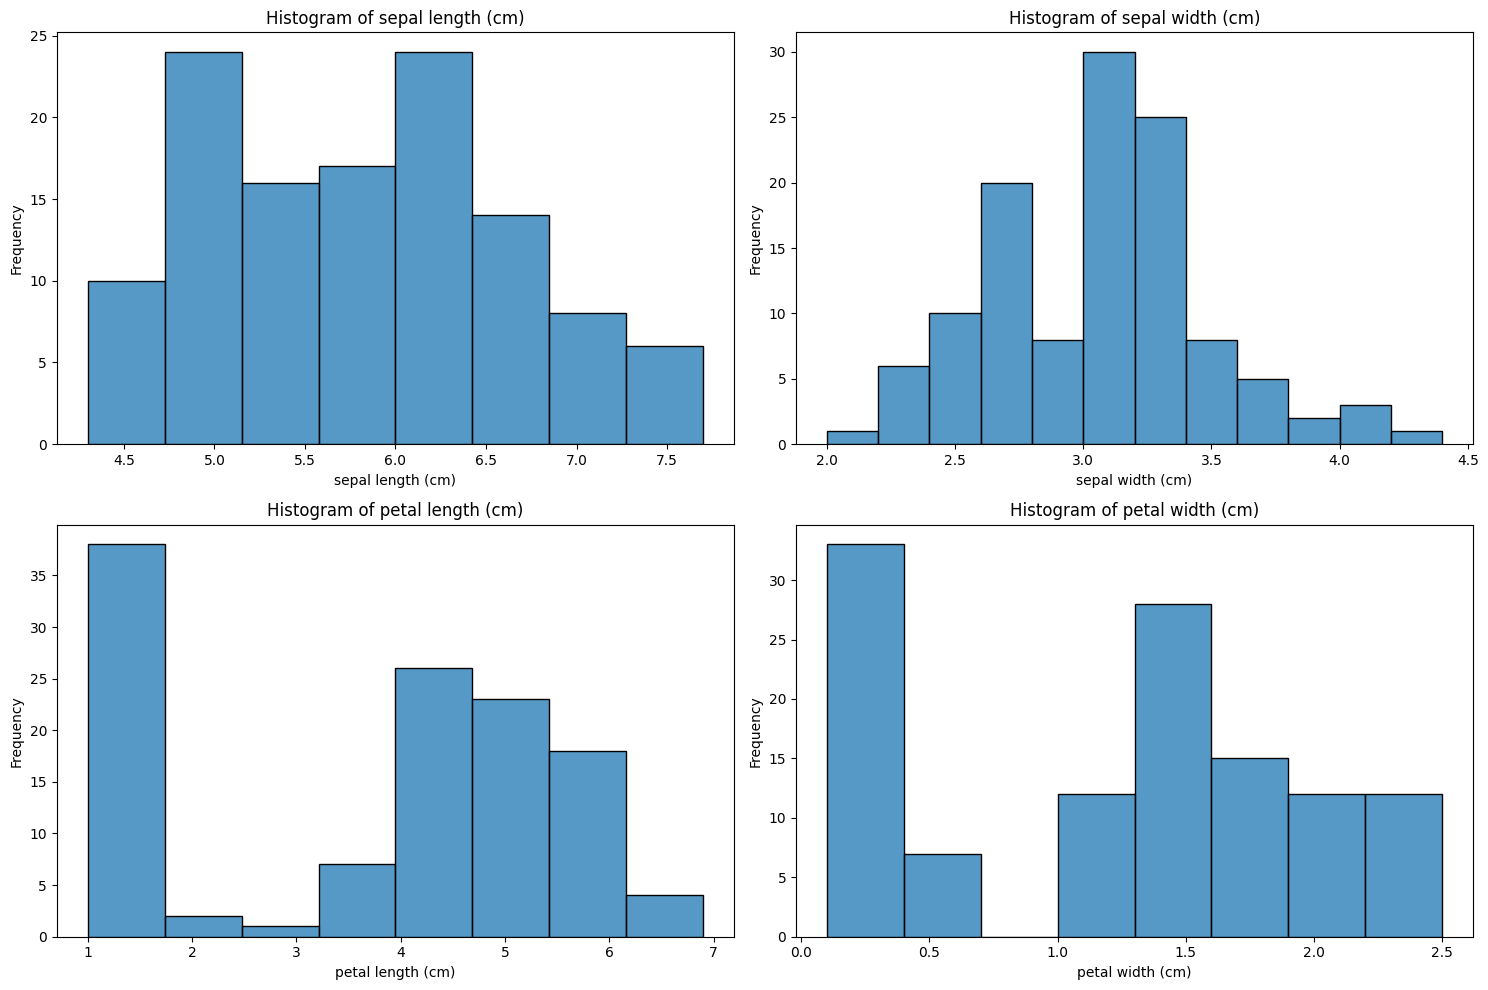

In [14]:
nums_cols = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
# set up
fig, axes= plt.subplots(2,2, figsize=(15,10))
axes= axes.flatten()
# loop
for i, col in enumerate(nums_cols):
    sns.histplot(data= trainset, x=col, ax=axes[i], palette='Set2')
    axes[i].set_title(f'Histogram of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
# remove the unuse subplot

plt.tight_layout()
plt.show

Sepal length (cm): Spans from 4.3 to 7.7 cm, displaying a bimodal distribution with peaks around 5.0 cm and 6.0–6.4 cm.   
Sepal width (cm): Spans from 2.0 to 4.4 cm, following a bell-shaped normal distribution centered around 3.0–3.2 cm.   
Petal length (cm): Spans from 1.0 to 6.9 cm, clearly split into two distinct clusters (1.0–1.8 cm and 3.0–6.9 cm).   
Petal width (cm): Spans from 0.1 to 2.5 cm, with a gap (0.7–1.0 cm) separating the data into two independent groups (0.1–0.6 cm and 1.0–2.5 cm).  

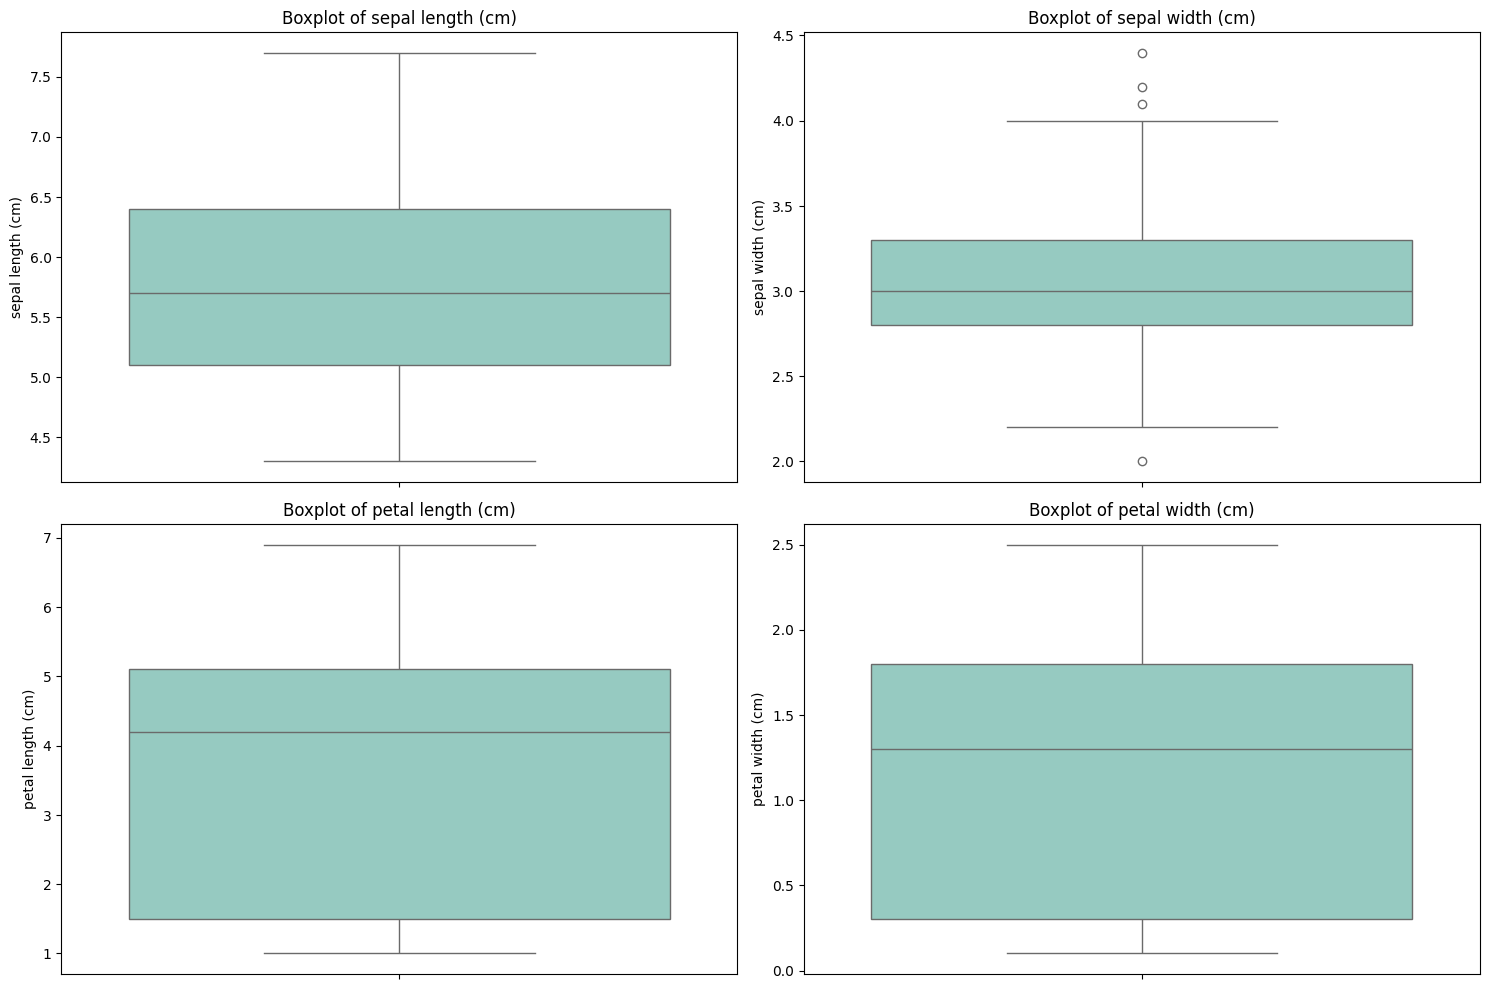

In [15]:
nums_cols = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
# Initialize a 2x2 grid for subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

# Loop through each column and plot a correct single boxplot
for i, col in enumerate(nums_cols):
    sns.boxplot(data=trainset, y=col, ax=axes[i], color='#8dd3c7')
    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_ylabel(col)

# Remove the unused subplot

plt.tight_layout()
plt.show()

##Bivariate

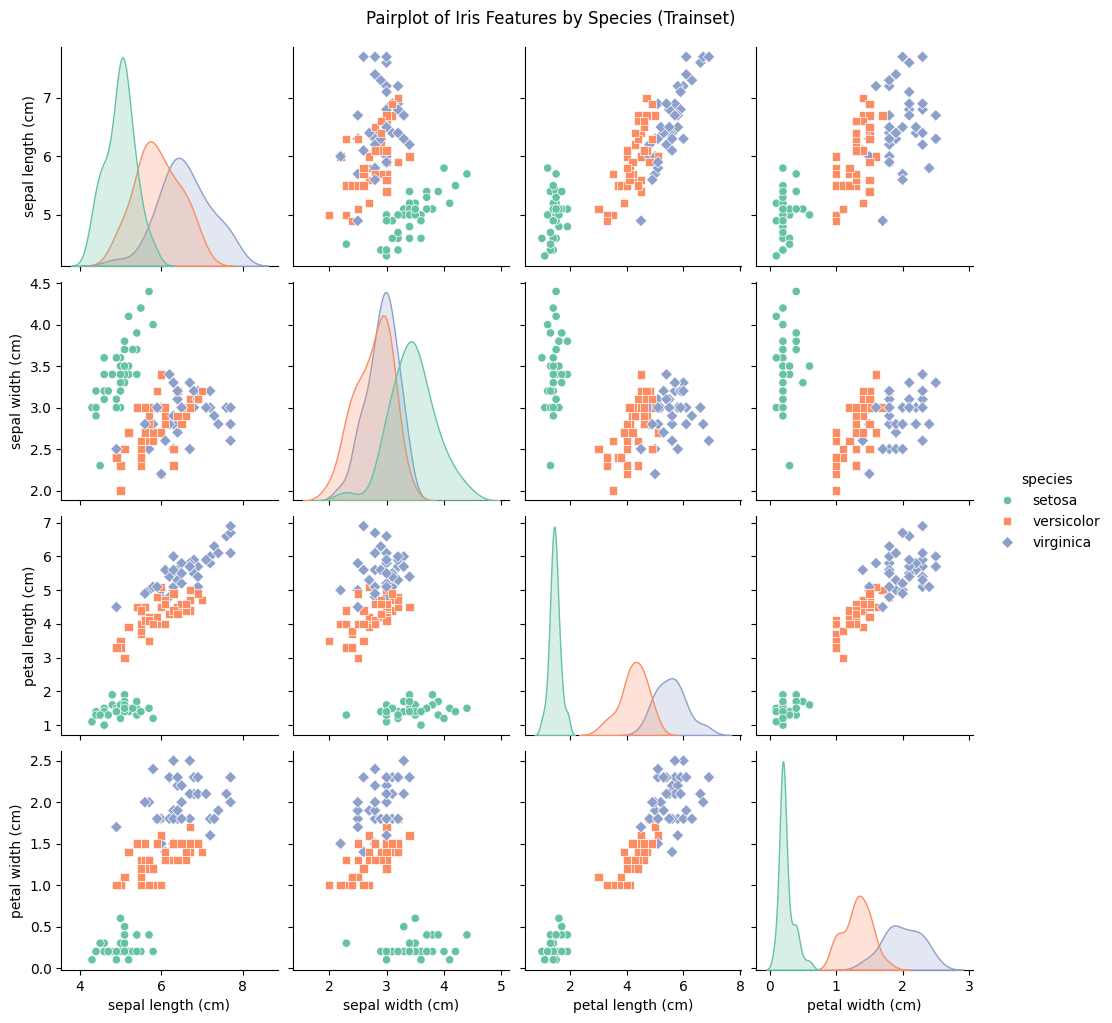

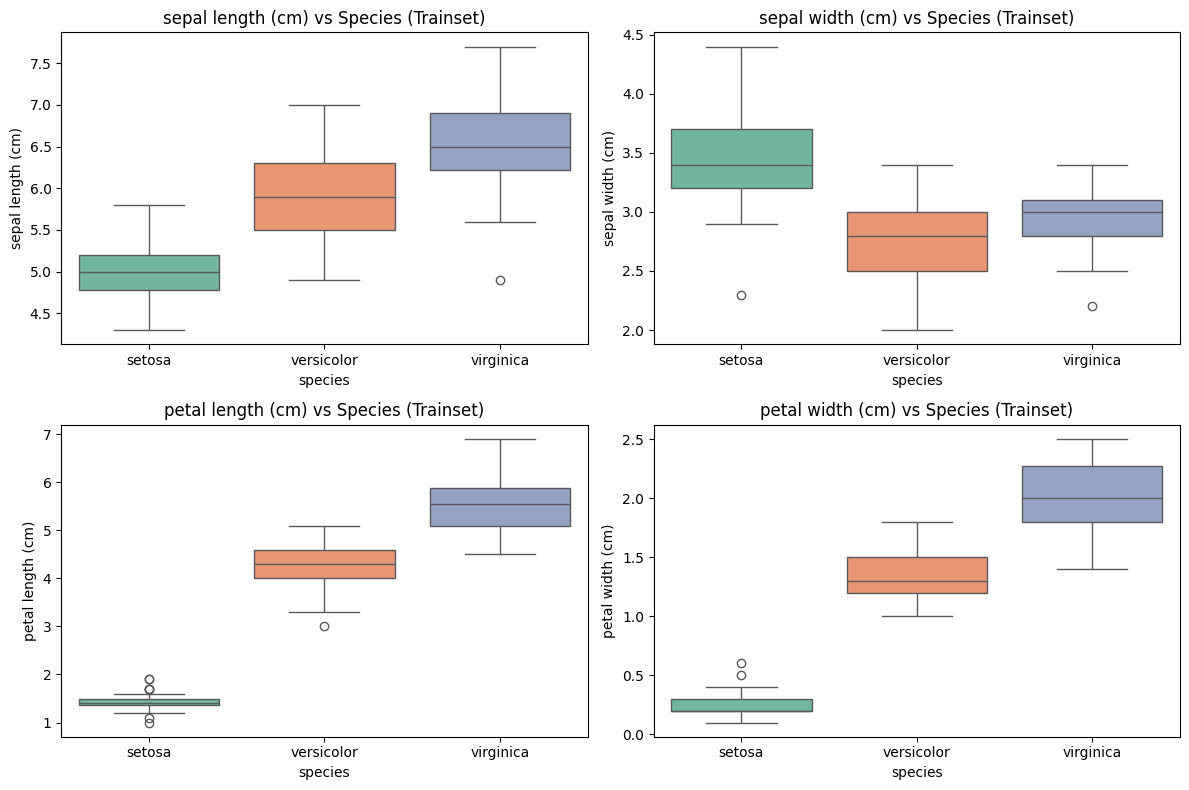

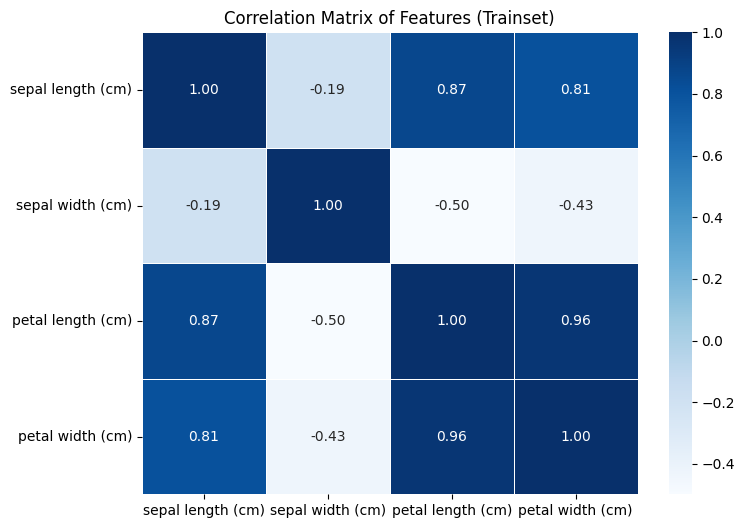

In [16]:
# 1. Pairplot - Pairwise relationships across all features grouped by species using trainset
sns.pairplot(trainset.drop(columns=['target']), hue='species', palette='Set2', markers=["o", "s", "D"])
plt.suptitle("Pairplot of Iris Features by Species (Trainset)", y=1.02)
plt.show()

# 2. Boxplot - Distribution of each feature across different species using trainset
features = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

plt.figure(figsize=(12, 8))
for i, col in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x='species', y=col, data=trainset, palette='Set2')
    plt.title(f'{col} vs Species (Trainset)')
plt.tight_layout()
plt.show()

# 3. Correlation Heatmap - Linear correlation matrix between numerical features using trainset
plt.figure(figsize=(8, 6))
correlation_matrix = trainset[features].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='Blues', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Features (Trainset)")
plt.show()

Petal Length & Petal Width (Best Discriminators): Setosa is completely separable from the other two species due to significantly smaller petal dimensions. Versicolor and virginica show only slight overlap, with virginica consistently having larger petals.   
Sepal Length: Shows an increasing trend from setosa to virginica, but has moderate overlap between versicolor and virginica.   Sepal Width: Setosa features distinctly wider sepals, whereas versicolor and virginica heavily overlap at lower values.   
Outliers: A few mild outliers are present (e.g., setosa petal values, virginica sepal length/width), but overall distributions are clean and well-structured.

## Handle Outlier

In [17]:
# Handle outlier
def remove_outliers(df, numeric_columns, threshold=1.5):
    df_no_outliers = df.copy()

    for column in numeric_columns:
        # Calculate IQR
        Q1 = df_no_outliers[column].quantile(0.25)
        Q3 = df_no_outliers[column].quantile(0.75)
        IQR = Q3 - Q1

        # Define bounds
        lower_bound = Q1 - threshold * IQR
        upper_bound = Q3 + threshold * IQR

        # Filter out outliers
        df_no_outliers = df_no_outliers[
            (df_no_outliers[column] >= lower_bound) & (df_no_outliers[column] <= upper_bound)
        ]

    return df_no_outliers


In [18]:
# Apply the function
trainset = remove_outliers(trainset, nums_cols)
trainset.shape

(115, 6)

In [19]:
testset = remove_outliers(testset, nums_cols)
testset.shape

(29, 6)

## Drop unused column

In [20]:
trainset = trainset.drop(columns=['species'])
testset = testset.drop(columns=['species'])

# Model development

## Agglomerative Clustering

In [21]:
X = trainset.drop(columns=['target'])
y = trainset['target']
#

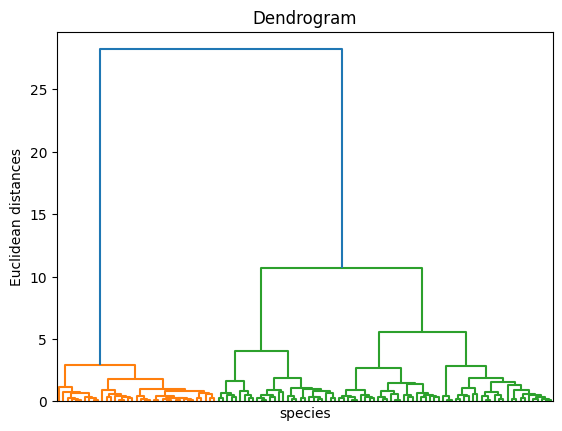

In [22]:
dendrogram = sch.dendrogram(sch.linkage(X, method='ward', metric='euclidean'), no_labels=True)
plt.title('Dendrogram')
plt.xlabel('species')
plt.ylabel('Euclidean distances')
plt.show()

##Model building

In [24]:
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters=3, linkage='ward', metric='euclidean')
hc.fit(X)

AgglomerativeClustering(n_clusters=3)

## Visualising the cluters

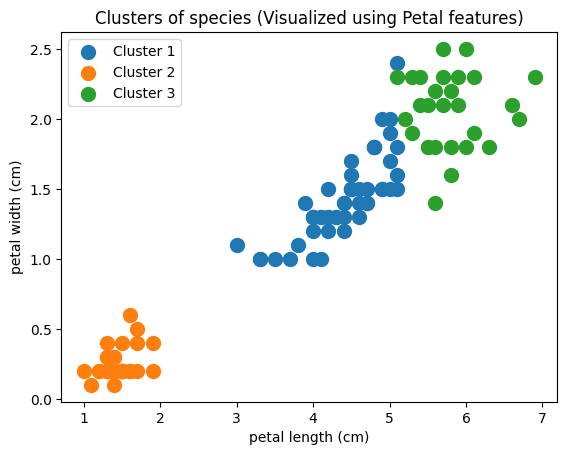

In [26]:
for i in range(3):
    plt.scatter(X[hc.labels_ == i]['petal length (cm)'], X[hc.labels_ == i]['petal width (cm)'], s=100, label=f'Cluster {i+1}')

plt.title('Clusters of species (Visualized using Petal features)')
plt.xlabel('petal length (cm)')
plt.ylabel('petal width (cm)')
plt.legend()
plt.show()

In [28]:
labels = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X)

df_out = X.copy()
df_out['cluster_label'] = labels

df_out

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),cluster_label
22,4.6,3.6,1.0,0.2,1
65,6.7,3.1,4.4,1.4,0
11,4.8,3.4,1.6,0.2,1
42,4.4,3.2,1.3,0.2,1
105,7.6,3.0,6.6,2.1,2
...,...,...,...,...,...
71,6.1,2.8,4.0,1.3,0
106,4.9,2.5,4.5,1.7,0
14,5.8,4.0,1.2,0.2,1
92,5.8,2.6,4.0,1.2,0


In [29]:
# Define the mapping from cluster numbers to actual species names
# Based on clustering characteristics:
# Cluster 1 corresponds to 'setosa'
# Cluster 0 corresponds to 'versicolor'
# Cluster 2 corresponds to 'virginica'
cluster_mapping = {
    1: 'setosa',
    0: 'versicolor',
    2: 'virginica'
}

# Map the predicted cluster labels to flower names
df_out['cluster_species'] = df_out['cluster_label'].map(cluster_mapping)

# Display the updated DataFrame with species name labels
df_out.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),cluster_label,cluster_species
22,4.6,3.6,1.0,0.2,1,setosa
65,6.7,3.1,4.4,1.4,0,versicolor
11,4.8,3.4,1.6,0.2,1,setosa
42,4.4,3.2,1.3,0.2,1,setosa
105,7.6,3.0,6.6,2.1,2,virginica


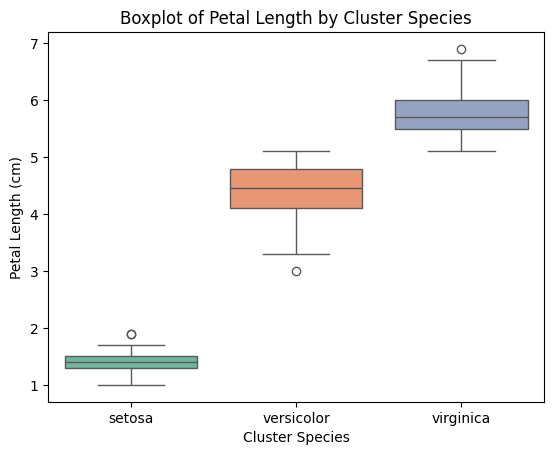

In [32]:
sns.boxplot(data=df_out, x='cluster_species', y='petal length (cm)', hue='cluster_species', palette='Set2')
plt.title('Boxplot of Petal Length by Cluster Species')
plt.xlabel('Cluster Species')
plt.ylabel('Petal Length (cm)')
plt.show()

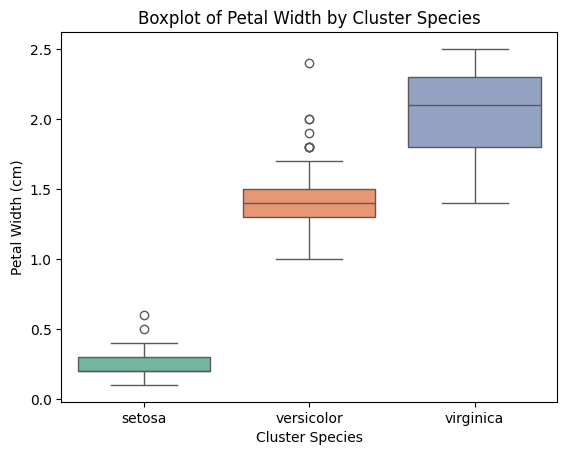

In [33]:
sns.boxplot(data=df_out, x='cluster_species', y='petal width (cm)', hue='cluster_species', palette='Set2')
plt.title('Boxplot of Petal Width by Cluster Species')
plt.xlabel('Cluster Species')
plt.ylabel('Petal Width (cm)')
plt.show()

## Model evaluation

In [34]:
from sklearn.metrics import silhouette_score
sil= silhouette_score(X, hc.labels_)
sil

np.float64(0.5512127957619123)

#K-MEANS

Text(0, 0.5, 'WCSS')

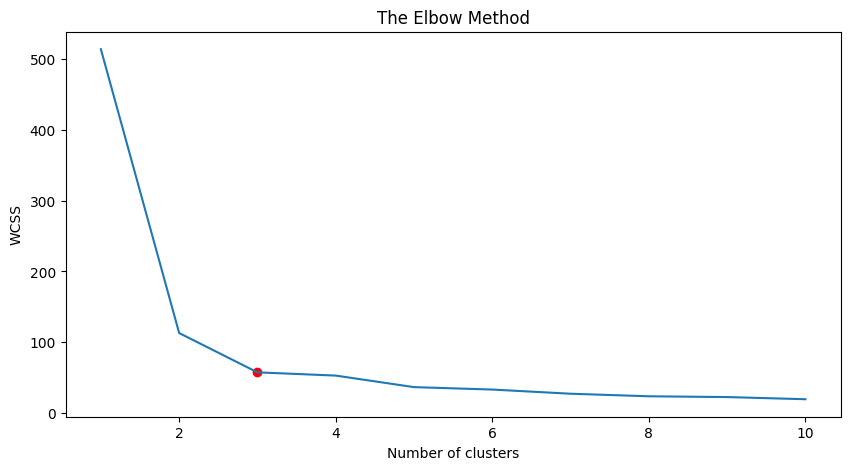

In [40]:
from sklearn.cluster import KMeans

wcss= []
for i in range(1, 11):
  kmeans= KMeans(n_clusters=i, init='k-means++', random_state=42)
  kmeans.fit(X)
  wcss.append(kmeans.inertia_)

plt.figure(figsize=(10,5))
plt.plot(range(1,11), wcss)
plt.scatter(3, wcss[2], color='red', label='Elbow Point')
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')

## Model Building

In [41]:
labels= KMeans(n_clusters=3, random_state=42).fit_predict(X)

In [43]:
# Create df_out as a copy of X (115 rows) to avoid index length mismatch with labels
df_out = X.copy()
df_out['cluster_label'] = labels

# Correct the syntax error by printing the value counts without treating df_out as a function
print(df_out['cluster_label'].value_counts().sort_index())

cluster_label
0    44
1    37
2    34
Name: count, dtype: int64


In [44]:
df_out.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),cluster_label
22,4.6,3.6,1.0,0.2,1
65,6.7,3.1,4.4,1.4,0
11,4.8,3.4,1.6,0.2,1
42,4.4,3.2,1.3,0.2,1
105,7.6,3.0,6.6,2.1,2


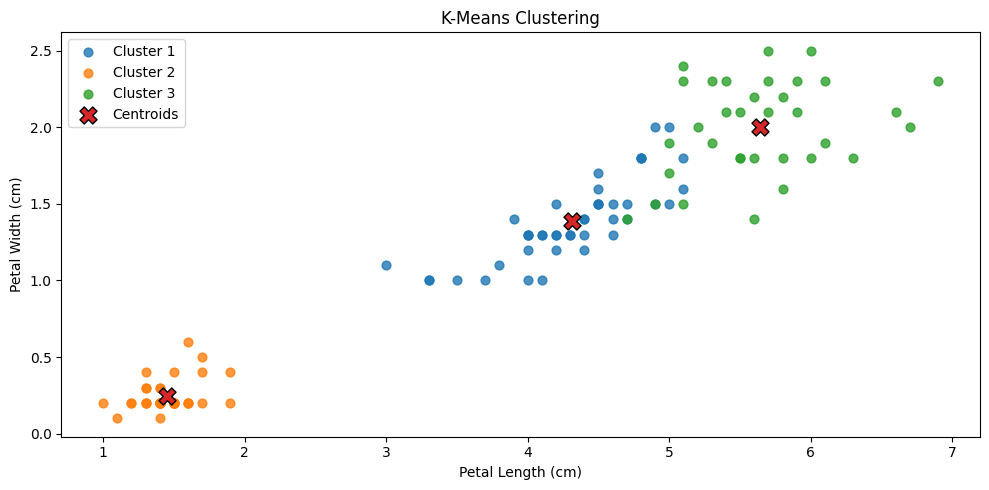

In [48]:
from sklearn.cluster import KMeans

# Fit KMeans model with optimal number of clusters (3)
kmeans_model = KMeans(n_clusters=3, random_state=42)
kmeans_model.fit(X)

# Get predictions and centroids
labels = kmeans_model.labels_
center = kmeans_model.cluster_centers_

# Convert DataFrame X to numpy array for easier 2D indexing
X_arr = X.values

plt.figure(figsize=(10,5))
for i in range(3):
    # Fix the missing comma syntax error and pandas indexing
    plt.scatter(X_arr[labels == i, 2], X_arr[labels == i, 3],
                s=40, alpha=0.8, label=f'Cluster {i+1}')

# Plot centroids using the correct feature indices (petal length and petal width are columns 2 and 3)
plt.scatter(center[:, 2], center[:, 3],
            s=150, marker='X', edgecolor='k', linewidths=1, label='Centroids')

plt.title('K-Means Clustering')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend()
plt.tight_layout()
plt.show()

In [49]:
# Define the mapping from cluster numbers to actual species names
# Based on clustering characteristics:
# Cluster 1 corresponds to 'setosa'
# Cluster 0 corresponds to 'versicolor'
# Cluster 2 corresponds to 'virginica'
cluster_mapping = {
    1: 'setosa',
    0: 'versicolor',
    2: 'virginica'
}

# Map the predicted cluster labels to flower names
df_out['cluster_species'] = df_out['cluster_label'].map(cluster_mapping)

# Display the updated DataFrame with species name labels
df_out.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),cluster_label,cluster_species
22,4.6,3.6,1.0,0.2,1,setosa
65,6.7,3.1,4.4,1.4,0,versicolor
11,4.8,3.4,1.6,0.2,1,setosa
42,4.4,3.2,1.3,0.2,1,setosa
105,7.6,3.0,6.6,2.1,2,virginica


In [51]:
# Model evaluation
from sklearn.metrics import silhouette_score
# K-MEANS
sil_k= silhouette_score(X, kmeans_model.labels_)
# Agglomarative Clutering
sil= silhouette_score(X, hc.labels_)
sil_k, sil



(np.float64(0.5439918384276883), np.float64(0.5512127957619123))

#Model winner is Agglomarative Clutering